## Experiment: test and interval from summary statistics.

In [1]:
import numpy as np
from scipy.stats import norm

mu_0 = 500.0
sigma = 12.0       # Known from separate calibration
n = 36
sample_mean = 505.0
alpha = 0.05

standard_error = sigma / np.sqrt(n)
z_observed = (sample_mean - mu_0) / standard_error
p_two_sided = 2 * norm.sf(abs(z_observed))
p_right = norm.sf(z_observed)
p_left = norm.cdf(z_observed)

critical = norm.isf(alpha / 2)
ci_low = sample_mean - critical * standard_error
ci_high = sample_mean + critical * standard_error

print(f"Standard error: {standard_error:.3f} g")
print(f"Observed z: {z_observed:.3f}")
print(f"Two-sided p-value: {p_two_sided:.6f}")
print(f"Right-sided p-value: {p_right:.6f}")
print(f"Left-sided p-value: {p_left:.6f}")
print(f"95% CI: [{ci_low:.3f}, {ci_high:.3f}] g")
print(f"Reject H0 at 5%: {p_two_sided < alpha}")

# Experiment: change the observed mean to 502 g.
# How do the p-value and confidence interval change?

Standard error: 2.000 g
Observed z: 2.500
Two-sided p-value: 0.012419
Right-sided p-value: 0.006210
Left-sided p-value: 0.993790
95% CI: [501.080, 508.920] g
Reject H0 at 5%: True


## Experiment: directional tests and a small sample.

In [2]:
import numpy as np
from scipy.stats import norm

# Left-sided normal-mean test using summary statistics.
mu_0 = 40.0
sigma = 8.0
n = 64
sample_mean = 38.0

z_left = (sample_mean - mu_0) / (sigma / np.sqrt(n))
p_left = norm.cdf(z_left)

print(f"Left-sided z: {z_left:.2f}")
print(f"Left-sided p-value: {p_left:.5f}")

# Small sample; exact because normality and known sigma are assumed.
observations = np.array([11.0, 12.0, 13.0, 12.0])
mu_0 = 10.0
sigma = 2.0

z_small = (
    observations.mean() - mu_0
) / (sigma / np.sqrt(len(observations)))
p_small = 2 * norm.sf(abs(z_small))

print(f"Small-sample z: {z_small:.2f}")
print(f"Small-sample two-sided p-value: {p_small:.5f}")

# Experiment: compare p_left and the two-sided p-value
# for the same observed statistic.

Left-sided z: -2.00
Left-sided p-value: 0.02275
Small-sample z: 2.00
Small-sample two-sided p-value: 0.04550


## Experiment: type I error when sigma is misspecified.

In [1]:
import numpy as np
from scipy.stats import norm

rng = np.random.default_rng(2026)
repetitions = 50_000
n = 36
mu_0 = 500.0
sigma_true = 12.0
sigma_wrong = 8.0
alpha = 0.05

# Under H0, simulate independent sample means directly.
means = rng.normal(
    loc=mu_0,
    scale=sigma_true / np.sqrt(n),
    size=repetitions
)

cutoff = norm.isf(alpha / 2)

z_correct = (means - mu_0) / (sigma_true / np.sqrt(n))
z_wrong = (means - mu_0) / (sigma_wrong / np.sqrt(n))

print("Nominal alpha:", alpha)
print("Correct sigma, empirical size:", np.mean(np.abs(z_correct) >= cutoff))
print("Wrong sigma, empirical size:", np.mean(np.abs(z_wrong) >= cutoff))
print(
    "Wrong sigma, theoretical size:",
    2 * norm.sf(cutoff * sigma_wrong / sigma_true)
)

# Experiment: use a sigma that is too large instead.
# Does the test become conservative?

Nominal alpha: 0.05
Correct sigma, empirical size: 0.04918
Wrong sigma, empirical size: 0.19078
Wrong sigma, theoretical size: 0.19133410234046078


## Experiment: normal approximation for skewed observations.

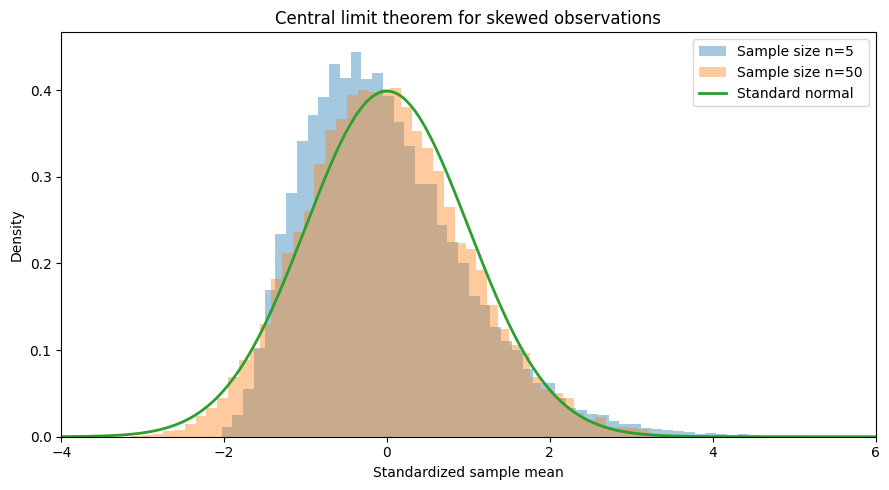

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(2026)
repetitions = 20_000

fig, ax = plt.subplots(figsize=(9, 5))

for n in (5, 50):
    samples = rng.exponential(
        scale=1.0, size=(repetitions, n)
    )
    standardized_means = np.sqrt(n) * (
        samples.mean(axis=1) - 1.0
    )

    ax.hist(
        standardized_means,
        bins=65,
        density=True,
        alpha=0.4,
        label=f"Sample size n={n}"
    )

x = np.linspace(-4, 6, 600)
ax.plot(x, norm.pdf(x), linewidth=2, label="Standard normal")
ax.set_xlim(-4, 6)
ax.set_xlabel("Standardized sample mean")
ax.set_ylabel("Density")
ax.set_title("Central limit theorem for skewed observations")
ax.legend()

fig.tight_layout()
fig.savefig(
    "../../images/known_sigma_clt_comparison.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# Experiment: try n=2, 10, 100 and compare the shapes.

## Experiment: coverage of known-sigma confidence intervals.

Nominal coverage: 95.0%
Empirical coverage: 95.02%


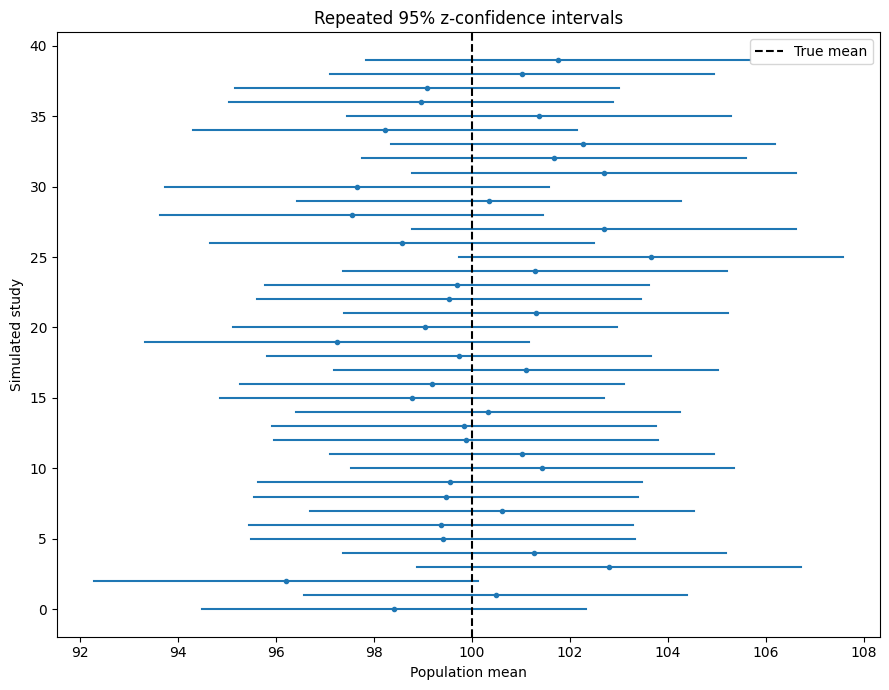

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(2026)
mu = 100.0
sigma = 10.0
n = 25
confidence_level = 0.95
repetitions = 20_000

standard_error = sigma / np.sqrt(n)
critical = norm.ppf((1 + confidence_level) / 2)

sample_means = rng.normal(
    mu, standard_error, size=repetitions
)
low = sample_means - critical * standard_error
high = sample_means + critical * standard_error
covers = (low <= mu) & (mu <= high)

print(f"Nominal coverage: {confidence_level:.1%}")
print(f"Empirical coverage: {covers.mean():.2%}")

# Plot the first 40 simulated confidence intervals.
fig, ax = plt.subplots(figsize=(9, 7))

for index in range(40):
    color = "C0" if covers[index] else "C3"
    ax.plot([low[index], high[index]], [index, index], color=color)
    ax.plot(sample_means[index], index, marker="o", color=color, markersize=3)

ax.axvline(mu, linestyle="--", color="black", label="True mean")
ax.set_xlabel("Population mean")
ax.set_ylabel("Simulated study")
ax.set_title("Repeated 95% z-confidence intervals")
ax.legend()

fig.tight_layout()
fig.savefig(
    "../../images/known_sigma_confidence_interval_coverage.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# Experiment: try 90% and 99% confidence levels.
# How do the interval widths and coverage change?

## Experiment: power and sample-size planning.

n=  9: power=0.2395
n= 36: power=0.7054
n= 46: power=0.8068
n=100: power=0.9863
Approximate sample size: 45.21
Smallest integer n with 80% power: 46


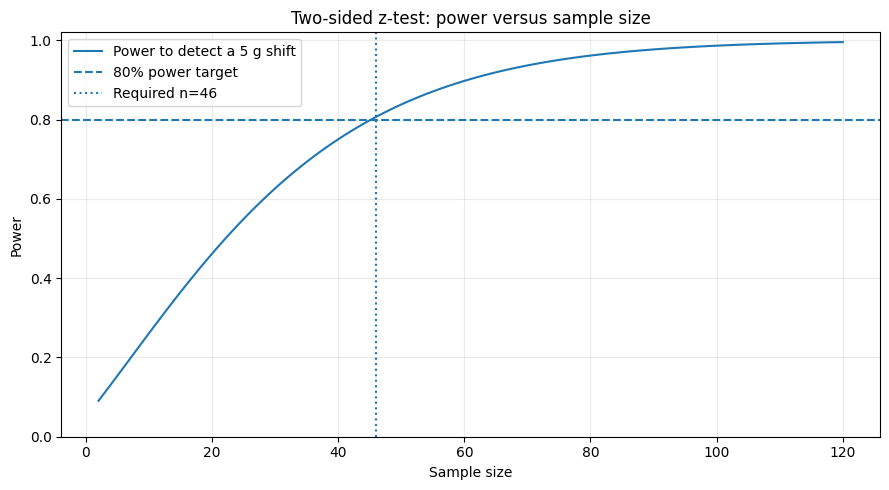

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

mu_0 = 500.0
mu_true = 505.0
sigma = 12.0
alpha = 0.05
target_power = 0.80


def two_sided_power(n, mu_1, mu_0, sigma, alpha=0.05):
    critical = norm.isf(alpha / 2)
    delta = np.sqrt(n) * (mu_1 - mu_0) / sigma
    return norm.cdf(-critical - delta) + norm.sf(critical - delta)


for n in (9, 36, 46, 100):
    power = two_sided_power(n, mu_true, mu_0, sigma, alpha)
    print(f"n={n:3d}: power={power:.4f}")

approximate_n = (
    sigma * (norm.isf(alpha / 2) + norm.ppf(target_power))
    / abs(mu_true - mu_0)
) ** 2

required_n = next(
    n for n in range(2, 1000)
    if two_sided_power(n, mu_true, mu_0, sigma, alpha) >= target_power
)

print(f"Approximate sample size: {approximate_n:.2f}")
print(f"Smallest integer n with 80% power: {required_n}")

sample_sizes = np.arange(2, 121)
powers = [
    two_sided_power(n, mu_true, mu_0, sigma, alpha)
    for n in sample_sizes
]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sample_sizes, powers, label="Power to detect a 5 g shift")
ax.axhline(target_power, linestyle="--", label="80% power target")
ax.axvline(required_n, linestyle=":", label=f"Required n={required_n}")
ax.set_xlabel("Sample size")
ax.set_ylabel("Power")
ax.set_ylim(0, 1.02)
ax.set_title("Two-sided z-test: power versus sample size")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    "../../images/known_sigma_power_sample_size.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# Experiment: double sigma. How many observations are needed?

 ## Experiment: illustrative z-calculation with student weights.

In [7]:
import numpy as np
import pandas as pd
from scipy.stats import norm

url = (
    "https://userpage.fu-berlin.de/"
    "soga/data/raw-data/students.csv"
)
students = pd.read_csv(url)

weights = students["weight"].dropna()
subsample = weights.sample(n=14, random_state=8)

mu_0 = 70.8
sigma_from_dataset = weights.std(ddof=0)
sample_mean = subsample.mean()
n = len(subsample)

z_illustrative = (
    (sample_mean - mu_0) / (sigma_from_dataset / np.sqrt(n))
)
p_illustrative = 2 * norm.sf(abs(z_illustrative))

print(f"Recorded-dataset SD: {sigma_from_dataset:.3f}")
print(f"Subsample mean: {sample_mean:.3f}")
print(f"Illustrative z: {z_illustrative:.3f}")
print(f"Illustrative two-sided p-value: {p_illustrative:.4f}")

Recorded-dataset SD: 8.635
Subsample mean: 69.821
Illustrative z: -0.424
Illustrative two-sided p-value: 0.6715
